In [1]:
!pip install pymupdf4llm deep-translator markdown weasyprint

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.0/69.0 MB 415.5 kB/s  0:09:54
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 472.8 kB/s  0:00:04
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.4/829.4 kB 636.8 kB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 347.5 kB/s  0:01:04
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [pymupdf4llm]


In [2]:
import os
import re
from deep_translator import GoogleTranslator
import markdown
import pymupdf4llm
from weasyprint import HTML

def extract_pdf_to_md(pdf_path, output_dir="output"):
    """
    1. استخراج الـ Markdown والصور من الـ PDF الأصلي
    """
    os.makedirs(output_dir, exist_ok=True)
    images_dir = os.path.join(output_dir, "images")
    os.makedirs(images_dir, exist_ok=True)

    print(f"[*] جاري استخراج النص والصور من {pdf_path}...")

    # pymupdf4llm يستخرج النص بصيغة markdown ويحفظ الصور في المجلد المحدد
    md_text = pymupdf4llm.to_markdown(
        pdf_path,
        write_images=True,
        image_path=images_dir,
        image_format="png"
    )

    md_file_path = os.path.join(output_dir, "original.md")
    with open(md_file_path, "w", encoding="utf-8") as f:
        f.write(md_text)

    print(f"[+] تم استخراج النص وحفظ الصور في مجلد: {images_dir}")
    return md_text, images_dir

def translate_markdown_text(text, chunk_size=3500):
    """
    2. ترجمة نص Markdown إلى العربية مع الحفاظ على علامات الصور والروابط
    """
    translator = GoogleTranslator(source="auto", target="ar")
    lines = text.split("\n")
    translated_lines = []

    print("[*] جاري الترجمة إلى اللغة العربية...")

    # نمط regex لاكتشاف الصور: ![alt](path)
    img_pattern = re.compile(r"!\[(.*?)\]\((.*?)\)")

    buffer = ""

    def flush_buffer(buf):
        if not buf.strip():
            return ""
        try:
            return translator.translate(buf)
        except Exception as e:
            print(f"[!] خطأ أثناء ترجمة مقطع: {e}")
            return buf

    for line in lines:
        stripped = line.strip()

        # إذا كان السطر صورة، نحافظ على مسار الصورة كما هو ونترجم الوصف فقط
        img_match = img_pattern.match(stripped)
        if img_match:
            # ترجمة ما تم تجميعه مسبقاً
            if buffer:
                translated_lines.append(flush_buffer(buffer))
                buffer = ""

            alt_text, img_src = img_match.groups()
            translated_alt = translator.translate(alt_text) if alt_text else ""
            translated_lines.append(f"![{translated_alt}]({img_src})")
            continue

        # إذا كان السطر كود برمجي أو فارغ
        if stripped.startswith("```") or stripped.startswith("---"):
            if buffer:
                translated_lines.append(flush_buffer(buffer))
                buffer = ""
            translated_lines.append(line)
            continue

        # تجميع الأسطر لتقليل عدد طلبات الترجمة وتسريع العملية
        if len(buffer) + len(line) < chunk_size:
            buffer += line + "\n"
        else:
            translated_lines.append(flush_buffer(buffer))
            buffer = line + "\n"

    if buffer:
        translated_lines.append(flush_buffer(buffer))

    return "\n".join(translated_lines)

def convert_md_to_pdf(translated_md, output_pdf_path, base_url="."):
    """
    3. تحويل الـ Markdown المترجم إلى HTML مع دعم RTL ثم إلى PDF
    """
    print("[*] جاري تحويل الـ Markdown إلى ملف PDF عربي...")

    # تحويل Markdown إلى HTML
    html_body = markdown.markdown(translated_md, extensions=['tables', 'fenced_code'])

    # قالب HTML مخصص يدعم العربية (RTL) وخط أميري وتنسيق الصور
    full_html = f"""
    <!DOCTYPE html>
    <html dir="rtl" lang="ar">
    <head>
        <meta charset="utf-8">
        <style>
            @import url('https://fonts.googleapis.com/css2?family=Amiri:ital,wght@0,400;0,700;1,400&display=swap');

            @page {{
                size: A4;
                margin: 20mm;
            }}
            body {{
                font-family: 'Amiri', 'Traditional Arabic', Tahoma, sans-serif;
                direction: rtl;
                text-align: right;
                font-size: 13pt;
                line-height: 1.8;
                color: #222;
            }}
            h1, h2, h3, h4, h5, h6 {{
                color: #1a1a1a;
                margin-top: 1.5em;
                margin-bottom: 0.5em;
            }}
            img {{
                max-width: 90%;
                height: auto;
                display: block;
                margin: 25px auto;
                border-radius: 4px;
            }}
            p {{
                margin-bottom: 1em;
                text-align: justify;
            }}
            pre, code {{
                direction: ltr;
                text-align: left;
                background-color: #f4f4f4;
                font-family: monospace;
            }}
        </style>
    </head>
    <body>
        {html_body}
    </body>
    </html>
    """

    # كتابة ملف HTML مؤقت (اختياري للمعانية)
    html_file = output_pdf_path.replace(".pdf", ".html")
    with open(html_file, "w", encoding="utf-8") as f:
        f.write(full_html)

    # تحويل HTML إلى PDF مع ربط مجلد الصور عبر base_url
    HTML(filename=html_file, base_url=base_url).write_pdf(output_pdf_path)
    print(f"[+] تم إنشاء ملف الـ PDF بنجاح: {output_pdf_path}")

# ==================== التشغيل ====================
if __name__ == "__main__":
    # اسم الملف الأصلي المراد ترجمته
    INPUT_PDF = "1_1-5.pdf"
    OUTPUT_FOLDER = "book_translated_project"
    FINAL_PDF = os.path.join(OUTPUT_FOLDER, "translated_book_ar.pdf")

    # 1. الاستخراج
    original_md, images_path = extract_pdf_to_md(INPUT_PDF, output_dir=OUTPUT_FOLDER)

    # 2. الترجمة
    translated_md = translate_markdown_text(original_md)

    # حفظ الـ Markdown المترجم
    translated_md_file = os.path.join(OUTPUT_FOLDER, "translated.md")
    with open(translated_md_file, "w", encoding="utf-8") as f:
        f.write(translated_md)

    # 3. التحويل إلى PDF مع الصور والتنسيق العربي
    convert_md_to_pdf(translated_md, FINAL_PDF, base_url=OUTPUT_FOLDER)

[*] جاري استخراج النص والصور من 1_1-5.pdf...

=== Document parser messages ===
Using Tesseract for OCR processing.
OCR on page.number=1/2.
[+] تم استخراج النص وحفظ الصور في مجلد: book_translated_project/images
[*] جاري الترجمة إلى اللغة العربية...
[!] خطأ أثناء ترجمة مقطع: Server Error: You made too many requests to the server.According to google, you are allowed to make 5 requests per secondand up to 200k requests per day. You can wait and try again later oryou can try the translate_batch function
[!] خطأ أثناء ترجمة مقطع: Server Error: You made too many requests to the server.According to google, you are allowed to make 5 requests per secondand up to 200k requests per day. You can wait and try again later oryou can try the translate_batch function
[!] خطأ أثناء ترجمة مقطع: Server Error: You made too many requests to the server.According to google, you are allowed to make 5 requests per secondand up to 200k requests per day. You can wait and try again later oryou can try the translate

ERROR:weasyprint:Failed to load image at 'file:///content/book_translated_project/book_translated_project/images/1_1-5.pdf-0002-06.png': URLError: <urlopen error [Errno 2] No such file or directory: '/content/book_translated_project/book_translated_project/images/1_1-5.pdf-0002-06.png'>


[+] تم إنشاء ملف الـ PDF بنجاح: book_translated_project/translated_book_ar.pdf


In [3]:
import os
import re
import time
from deep_translator import GoogleTranslator
import markdown
import pymupdf4llm
from weasyprint import HTML

def clean_gutenberg_garbage(text):
    """حذف شوائب طباعة المتصفح وتذييلات جوتنبرج"""
    cleaned_lines = []
    for line in text.splitlines():
        # استبعاد الأسطر المشوهة وسجلات الطباعة
        if re.search(r'\d{2}:\d{2}\s*,\s*\d+/\d+/\d+', line): # تاريخ ووقت
            continue
        if re.search(r'of\s+\d+\s+\d+', line): # ترقيم صفحات متصفح
            continue
        if "pg23989" in line or "gutenberg.org/cache" in line:
            continue
        # استبعاد الرموز المكسورة مثل: 2S ee $ Hs; LS
        if re.match(r'^[A-Za-z0-9\s\$\;\,\(\)\=\*\-\\\"]{15,}$', line.strip()) and " " in line and len(line.split()) > 4:
            words = line.strip().split()
            if all(len(w) <= 3 for w in words): # كلمات عشوائية من حرف أو حرفين
                continue
        cleaned_lines.append(line)
    return "\n".join(cleaned_lines)

def safe_translate(text, translator):
    """ترجمة نص مع محاولة إعادة المحاولة في حال الخطأ"""
    if not text.strip():
        return ""
    for attempt in range(3):
        try:
            return translator.translate(text)
        except Exception:
            time.sleep(1)
    return text  # إذا فشل يعيد النص الأصلي

def extract_and_clean_pdf(pdf_path, output_dir="output"):
    os.makedirs(output_dir, exist_ok=True)
    images_dir = os.path.join(output_dir, "images")
    os.makedirs(images_dir, exist_ok=True)

    print("[*] 1. جاري استخراج النص والصور...")
    raw_md = pymupdf4llm.to_markdown(
        pdf_path,
        write_images=True,
        image_path=images_dir,
        image_format="png"
    )

    clean_md = clean_gutenberg_garbage(raw_md)
    return clean_md, images_dir

def translate_markdown(text):
    print("[*] 2. جاري الترجمة إلى العربية (يرجى الانتظار)...")
    translator = GoogleTranslator(source="en", target="ar")
    lines = text.split("\n")
    translated_lines = []

    img_pattern = re.compile(r"!\[(.*?)\]\((.*?)\)")

    for line in lines:
        stripped = line.strip()
        if not stripped:
            translated_lines.append("")
            continue

        # الحفاظ على الصور
        img_match = img_pattern.match(stripped)
        if img_match:
            alt, src = img_match.groups()
            translated_lines.append(f"![{alt}]({src})")
            continue

        # ترجمة الفقرات العادية
        if len(stripped) > 2:
            ar_line = safe_translate(stripped, translator)
            translated_lines.append(ar_line)
            time.sleep(0.2)  # مهلة لتفادي حظر جوجل
        else:
            translated_lines.append(line)

    return "\n".join(translated_lines)

def build_arabic_pdf(md_content, output_pdf, base_url="."):
    print("[*] 3. جاري توليد ملف الـ PDF النهائي...")
    html_body = markdown.markdown(md_content, extensions=['tables', 'fenced_code'])

    html_template = f"""
    <!DOCTYPE html>
    <html dir="rtl" lang="ar">
    <head>
        <meta charset="utf-8">
        <style>
            @import url('https://fonts.googleapis.com/css2?family=Cairo:wght@400;600;700&display=swap');
            @page {{
                size: A4;
                margin: 25mm 20mm;
                @bottom-center {{
                    content: counter(page);
                    font-family: 'Cairo', sans-serif;
                    font-size: 10pt;
                }}
            }}
            body {{
                font-family: 'Cairo', Tahoma, sans-serif;
                direction: rtl;
                text-align: right;
                font-size: 11pt;
                line-height: 1.8;
                color: #2b2b2b;
            }}
            h1, h2, h3 {{
                text-align: center;
                color: #111;
                margin-top: 25px;
                margin-bottom: 15px;
            }}
            p {{
                text-align: justify;
                margin-bottom: 12px;
            }}
            img {{
                max-width: 80%;
                display: block;
                margin: 20px auto;
            }}
        </style>
    </head>
    <body>
        {html_body}
    </body>
    </html>
    """
    HTML(string=html_template, base_url=base_url).write_pdf(output_pdf)
    print(f"[+] تم الانتهاء بنجاح! الملف جاهز: {output_pdf}")

if __name__ == "__main__":
    PDF_FILE = "1_1-5.pdf"       # ضع اسم ملفك هنا
    PROJECT_DIR = "book_output"
    RESULT_PDF = os.path.join(PROJECT_DIR, "Arabic_Book.pdf")

    # تنفيذ الخطوات
    md_text, img_dir = extract_and_clean_pdf(PDF_FILE, PROJECT_DIR)
    ar_md = translate_markdown(md_text)
    build_arabic_pdf(ar_md, RESULT_PDF, base_url=PROJECT_DIR)

[*] 1. جاري استخراج النص والصور...

=== Document parser messages ===
Using Tesseract for OCR processing.
OCR on page.number=1/2.
[*] 2. جاري الترجمة إلى العربية (يرجى الانتظار)...
[*] 3. جاري توليد ملف الـ PDF النهائي...


ERROR:weasyprint:Failed to load image at 'file:///content/book_output/book_output/images/1_1-5.pdf-0002-06.png': URLError: <urlopen error [Errno 2] No such file or directory: '/content/book_output/book_output/images/1_1-5.pdf-0002-06.png'>


[+] تم الانتهاء بنجاح! الملف جاهز: book_output/Arabic_Book.pdf


In [4]:
import os
import re
import time
from deep_translator import GoogleTranslator
import markdown
import pymupdf4llm
from weasyprint import HTML

def step1_extract(pdf_path, output_dir):
    """استخراج Markdown والصور وحفظها بمسارات مطلقة"""
    os.makedirs(output_dir, exist_ok=True)
    images_dir = os.path.abspath(os.path.join(output_dir, "images"))
    os.makedirs(images_dir, exist_ok=True)

    print(f"[*] 1. جاري استخراج النص والصور من {pdf_path}...")
    md_text = pymupdf4llm.to_markdown(
        pdf_path,
        write_images=True,
        image_path=images_dir,
        image_format="png"
    )

    # التحقق من وجود صور مستخرجة
    extracted_images = os.listdir(images_dir)
    print(f"[+] تم استخراج {len(extracted_images)} صورة إلى: {images_dir}")

    # تحويل مسارات الصور داخل الـ Markdown إلى مسارات نظام مطلقة
    # لضمان قراءتها دون أي أخطاء في الـ PDF
    def fix_img_path(match):
        alt = match.group(1)
        src = match.group(2)
        # استخراج اسم الصورة فقط
        filename = os.path.basename(src)
        abs_path = os.path.join(images_dir, filename)
        return f"![{alt}](file://{abs_path})"

    md_text = re.sub(r"!\[(.*?)\]\((.*?)\)", fix_img_path, md_text)
    return md_text

def step2_translate(md_text):
    """ترجمة كتل النصوص مع عزل الصور وحمايتها"""
    print("[*] 2. جاري تجهيز النص وحماية وسوم الصور...")

    # عزل علامات الصور وحفظها في مصفوفة
    images_list = []
    def stash_image(match):
        idx = len(images_list)
        images_list.append(match.group(0))
        return f"\n\n__IMG_TOKEN_{idx}__\n\n"

    # استبدال كل صورة برمز مؤقت
    protected_text = re.sub(r"!\[.*?\]\(file://.*?\)", stash_image, md_text)

    # تقسيم النص إلى فقرات مجمعة
    paragraphs = protected_text.split("\n\n")
    chunks = []
    current_chunk = ""

    for p in paragraphs:
        if "__IMG_TOKEN_" in p:
            if current_chunk.strip():
                chunks.append(current_chunk.strip())
                current_chunk = ""
            chunks.append(p.strip())
        else:
            if len(current_chunk) + len(p) < 1800:
                current_chunk += p + "\n\n"
            else:
                chunks.append(current_chunk.strip())
                current_chunk = p + "\n\n"

    if current_chunk.strip():
        chunks.append(current_chunk.strip())

    print(f"[*] جاري ترجمة {len(chunks)} مقطع إلى العربية...")
    translator = GoogleTranslator(source="en", target="ar")
    translated_chunks = []

    for i, chunk in enumerate(chunks):
        if chunk.startswith("__IMG_TOKEN_"):
            translated_chunks.append(chunk)
            continue

        success = False
        for attempt in range(4):
            try:
                # محاولة الترجمة
                res = translator.translate(chunk)
                if res and any('\u0600' <= char <= '\u06FF' for char in res):
                    translated_chunks.append(res)
                    success = True
                    break
            except Exception as e:
                print(f"[!] خطأ اتصال في المقطع {i+1}، إعادة المحاولة بعد ثوانٍ...")
                time.sleep(3)

        if not success:
            raise RuntimeError(
                f"فشلت الترجمة عند المقطع {i+1}! خدمة جوجل حظرت الطلبات مؤقتاً. "
                "يرجى الانتظار 5 دقائق والمحاولة مرة أخرى أو استخدام VPN."
            )

        print(f"    - تم إنجاز {i+1}/{len(chunks)}")
        time.sleep(1.2)  # مهلة ضرورية جداً لحماية الـ IP من حظر جوجل

    # دمج النص وإرجاع الصور إلى أماكنها الأصلية
    full_translated = "\n\n".join(translated_chunks)
    for idx, img_tag in enumerate(images_list):
        full_translated = full_translated.replace(f"__IMG_TOKEN_{idx}__", img_tag)

    return full_translated

def step3_generate_pdf(translated_md, output_pdf):
    """تحويل الـ Markdown المترجم إلى PDF بتنسيق عربي فاخر"""
    print("[*] 3. جاري توليد ملف الـ PDF النهائي وتنسيق الصفحات...")

    html_body = markdown.markdown(translated_md, extensions=['tables', 'fenced_code'])

    html_template = f"""
    <!DOCTYPE html>
    <html dir="rtl" lang="ar">
    <head>
        <meta charset="utf-8">
        <style>
            @import url('https://fonts.googleapis.com/css2?family=Cairo:wght@400;600;700&family=Amiri:wght@400;700&display=swap');

            @page {{
                size: A4;
                margin: 25mm 20mm;
                @bottom-center {{
                    content: counter(page);
                    font-family: 'Cairo', sans-serif;
                    font-size: 10pt;
                    color: #666;
                }}
            }}
            body {{
                font-family: 'Amiri', 'Traditional Arabic', serif;
                direction: rtl;
                text-align: right;
                font-size: 13pt;
                line-height: 1.9;
                color: #222;
            }}
            h1, h2, h3 {{
                font-family: 'Cairo', sans-serif;
                text-align: center;
                color: #111;
                margin-top: 30px;
                margin-bottom: 15px;
            }}
            p {{
                text-align: justify;
                margin-bottom: 14px;
            }}
            /* تنسيق ظهور الصور في منتصف الصفحة */
            img {{
                max-width: 85%;
                max-height: 500px;
                display: block;
                margin: 25px auto;
                border: 1px solid #ddd;
                padding: 4px;
                box-shadow: 2px 2px 8px rgba(0,0,0,0.1);
            }}
        </style>
    </head>
    <body>
        {html_body}
    </body>
    </html>
    """

    HTML(string=html_template).write_pdf(output_pdf)
    print(f"\n[+] اكتملت العملية بنجاح! تم حفظ الملف المترجم في:\n{output_pdf}")

if __name__ == "__main__":
    # ضع مسار كتاب الـ PDF الأصلي هنا
    SOURCE_PDF = "a.pdf"
    WORKSPACE_DIR = "translated_project"
    FINAL_RESULT_PDF = os.path.join(WORKSPACE_DIR, "Book_Arabic_Final.pdf")

    # تنفيذ المراحل
    md_content = step1_extract(SOURCE_PDF, WORKSPACE_DIR)
    ar_translated_md = step2_translate(md_content)
    step3_generate_pdf(ar_translated_md, FINAL_RESULT_PDF)

[*] 1. جاري استخراج النص والصور من a.pdf...

=== Document parser messages ===
Using Tesseract for OCR processing.
OCR on page.number=1/2.
[+] تم استخراج 1 صورة إلى: /content/translated_project/images
[*] 2. جاري تجهيز النص وحماية وسوم الصور...
[*] جاري ترجمة 7 مقطع إلى العربية...
[!] خطأ اتصال في المقطع 1، إعادة المحاولة بعد ثوانٍ...
[!] خطأ اتصال في المقطع 1، إعادة المحاولة بعد ثوانٍ...
[!] خطأ اتصال في المقطع 1، إعادة المحاولة بعد ثوانٍ...
[!] خطأ اتصال في المقطع 1، إعادة المحاولة بعد ثوانٍ...


RuntimeError: فشلت الترجمة عند المقطع 1! خدمة جوجل حظرت الطلبات مؤقتاً. يرجى الانتظار 5 دقائق والمحاولة مرة أخرى أو استخدام VPN.

In [5]:
!apt-get install -y pango1.0-tools
!pip install pymupdf4llm markdown weasyprint transformers sentencepiece sacremoses rapidocr-onnxruntime

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Suggested packages:
  graphicsmagick
The following NEW packages will be installed:
  pango1.0-tools
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 36.7 kB of archives.
After this operation, 143 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd64 pango1.0-tools amd64 1.52.1+ds-1build1 [36.7 kB]
Fetched 36.7 kB in 1s (69.8 kB/s)
Selecting previously unselected package pango1.0-tools.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../pango1.0-tools_1.52.1+ds-1build1_amd64.deb ...
Unpacking pango1.0-tools (1.52.1+ds-1build1) ...
Setting up pango1.0-tools (1.52.1+ds-1build1) ...
Processing triggers for man-db (2.12.0-4build2) ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 867.8/867.8 kB 8.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 14.4 MB/s  0:00

In [6]:
import os
import re
import torch
import markdown
import pymupdf4llm
from weasyprint import HTML
from transformers import pipeline

# 1. تحميل نموذج الترجمة المجاني داخل Colab
print("[*] جاري تحميل نموذج الذكاء الاصطناعي للترجمة (حجمه خفيف ~300MB)...")
device = 0 if torch.cuda.is_available() else -1
translator = pipeline(
    "translation",
    model="Helsinki-NLP/opus-mt-en-ar",
    device=device
)
print(f"[+] تم تحميل النموذج بنجاح (يعمل على: {'GPU' if device == 0 else 'CPU'})")

def step1_extract(pdf_path, output_dir):
    """استخراج Markdown والصور وحفظها بمسارات مطلقة"""
    os.makedirs(output_dir, exist_ok=True)
    images_dir = os.path.abspath(os.path.join(output_dir, "images"))
    os.makedirs(images_dir, exist_ok=True)

    print(f"[*] 1. جاري استخراج النص والصور من {pdf_path}...")
    md_text = pymupdf4llm.to_markdown(
        pdf_path,
        write_images=True,
        image_path=images_dir,
        image_format="png"
    )

    extracted_images = os.listdir(images_dir)
    print(f"[+] تم استخراج {len(extracted_images)} صورة إلى: {images_dir}")

    # تحويل مسارات الصور إلى مسارات مطلقة تفهمها WeasyPrint
    def fix_img_path(match):
        alt = match.group(1)
        src = match.group(2)
        filename = os.path.basename(src)
        abs_path = os.path.join(images_dir, filename)
        return f"![{alt}](file://{abs_path})"

    md_text = re.sub(r"!\[(.*?)\]\((.*?)\)", fix_img_path, md_text)
    return md_text

def translate_sentence_by_sentence(text):
    """ترجمة النصوص عبر النموذج المحلي مع تقسيم الجمل لتفادي تجاوز طول السياق"""
    if not text.strip():
        return ""

    # تقسيم النص إلى جمل
    sentences = re.split(r'(?<=[.!?\n])\s+', text)
    translated_sentences = []

    for s in sentences:
        s_clean = s.strip()
        if not s_clean:
            continue
        try:
            # ترجمة الجملة عبر الموديل المحلي
            res = translator(s_clean, max_length=512)
            translated_sentences.append(res[0]['translation_text'])
        except Exception:
            translated_sentences.append(s_clean)

    return " ".join(translated_sentences)

def step2_translate(md_text):
    """حماية الصور وترجمة الكتل النصية"""
    print("[*] 2. جاري ترجمة النص إلى العربية بالنموذج المحلي...")

    images_list = []
    def stash_image(match):
        idx = len(images_list)
        images_list.append(match.group(0))
        return f"\n\n__IMG_TOKEN_{idx}__\n\n"

    # عزل علامات الصور
    protected_text = re.sub(r"!\[.*?\]\(file://.*?\)", stash_image, md_text)
    paragraphs = protected_text.split("\n\n")
    translated_paras = []

    total = len(paragraphs)
    for i, p in enumerate(paragraphs):
        p_strip = p.strip()
        if not p_strip:
            continue

        if "__IMG_TOKEN_" in p_strip:
            translated_paras.append(p_strip)
        else:
            ar_para = translate_sentence_by_sentence(p_strip)
            translated_paras.append(ar_para)

        if (i + 1) % 5 == 0 or (i + 1) == total:
            print(f"    - تقدم الترجمة: {i+1}/{total} فقرة")

    # استعادة الصور إلى مواضعها الأصلية
    full_translated = "\n\n".join(translated_paras)
    for idx, img_tag in enumerate(images_list):
        full_translated = full_translated.replace(f"__IMG_TOKEN_{idx}__", img_tag)

    return full_translated

def step3_generate_pdf(translated_md, output_pdf):
    """تحويل Markdown إلى PDF عربي مع تنسيق الصور والخطوط"""
    print("[*] 3. جاري توليد ملف الـ PDF النهائي...")

    html_body = markdown.markdown(translated_md, extensions=['tables', 'fenced_code'])

    html_template = f"""
    <!DOCTYPE html>
    <html dir="rtl" lang="ar">
    <head>
        <meta charset="utf-8">
        <style>
            @import url('https://fonts.googleapis.com/css2?family=Cairo:wght@400;600;700&family=Amiri:wght@400;700&display=swap');
            @page {{
                size: A4;
                margin: 20mm 18mm;
                @bottom-center {{
                    content: counter(page);
                    font-family: 'Cairo', sans-serif;
                    font-size: 10pt;
                }}
            }}
            body {{
                font-family: 'Amiri', 'Traditional Arabic', serif;
                direction: rtl;
                text-align: right;
                font-size: 13pt;
                line-height: 1.8;
                color: #222;
            }}
            h1, h2, h3 {{
                font-family: 'Cairo', sans-serif;
                text-align: center;
                margin-top: 25px;
            }}
            p {{
                text-align: justify;
                margin-bottom: 12px;
            }}
            img {{
                max-width: 80%;
                max-height: 480px;
                display: block;
                margin: 20px auto;
                border: 1px solid #ccc;
            }}
        </style>
    </head>
    <body>
        {html_body}
    </body>
    </html>
    """

    HTML(string=html_template).write_pdf(output_pdf)
    print(f"\n[+] اكتمل كل شيء بنجاح! تم إنشاء الملف العربي:\n{output_pdf}")

# ==================== التشغيل ====================
SOURCE_PDF = "a.pdf"
WORKSPACE_DIR = "/content/translated_project"
FINAL_RESULT_PDF = os.path.join(WORKSPACE_DIR, "a_arabic.pdf")

md_content = step1_extract(SOURCE_PDF, WORKSPACE_DIR)
ar_md = step2_translate(md_content)
step3_generate_pdf(ar_md, FINAL_RESULT_PDF)

[*] جاري تحميل نموذج الذكاء الاصطناعي للترجمة (حجمه خفيف ~300MB)...


config.json:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

KeyError: 'The task translation has been removed from transformers. Use the `text-generation` pipeline with a chat model instead. See the migration guide for more details: https://github.com/huggingface/transformers/blob/main/MIGRATION_GUIDE_V5.md#pipelines'

### شغال ترجم النص مع بقاء الصورة بجوار النص

In [8]:
import os
import re
import torch
import markdown
import pymupdf4llm
from weasyprint import HTML
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# 1. تحميل النموذج مباشرة وتجاوز مشاكل الـ pipeline القديم
print("[*] جاري تحميل النموذج والمجزئ اللغوي (Helsinki-NLP/opus-mt-en-ar)...")
model_name = "Helsinki-NLP/opus-mt-en-ar"

device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(device)
print(f"[+] تم تجهيز النموذج بنجاح وهو يعمل على: {device.upper()}")

def step1_extract(pdf_path, output_dir):
    """استخراج Markdown والصور وحفظها بمسارات مطلقة"""
    os.makedirs(output_dir, exist_ok=True)
    images_dir = os.path.abspath(os.path.join(output_dir, "images"))
    os.makedirs(images_dir, exist_ok=True)

    print(f"[*] 1. جاري استخراج النص والصور من {pdf_path}...")
    md_text = pymupdf4llm.to_markdown(
        pdf_path,
        write_images=True,
        image_path=images_dir,
        image_format="png"
    )

    extracted_images = os.listdir(images_dir)
    print(f"[+] تم استخراج {len(extracted_images)} صورة إلى مجلد: {images_dir}")

    # تحويل مسارات الصور إلى مسارات نظام مطلقة
    def fix_img_path(match):
        alt = match.group(1)
        src = match.group(2)
        filename = os.path.basename(src)
        abs_path = os.path.join(images_dir, filename)
        return f"![{alt}](file://{abs_path})"

    md_text = re.sub(r"!\[(.*?)\]\((.*?)\)", fix_img_path, md_text)
    return md_text

def translate_batch(text_chunk):
    """ترجمة الفقرة عبر تقسيمها لجمل ومعالجتها دفعة واحدة عبر الموديل"""
    if not text_chunk.strip():
        return ""

    # تقسيم الفقرة إلى جمل
    raw_sentences = re.split(r'(?<=[.!?\n])\s+', text_chunk)
    sentences = [s.strip() for s in raw_sentences if s.strip()]
    if not sentences:
        return ""

    try:
        # معالجة الجمل معاً على كارت الشاشة أو المعالج
        inputs = tokenizer(sentences, return_tensors="pt", padding=True, truncation=True, max_length=512).to(device)
        with torch.no_grad():
            translated_tokens = model.generate(**inputs)
        translated_sentences = tokenizer.batch_decode(translated_tokens, skip_special_tokens=True)
        return " ".join(translated_sentences)
    except Exception as e:
        print(f"[!] خطأ أثناء الترجمة: {e}")
        return text_chunk

def step2_translate(md_text):
    """حماية الصور وترجمة كتل النصوص"""
    print("[*] 2. جاري ترجمة النص إلى العربية بالذكاء الاصطناعي...")

    # عزل وسوم الصور حتى لا تتشوه أثناء الترجمة
    images_list = []
    def stash_image(match):
        idx = len(images_list)
        images_list.append(match.group(0))
        return f"\n\n__IMG_TOKEN_{idx}__\n\n"

    protected_text = re.sub(r"!\[.*?\]\(file://.*?\)", stash_image, md_text)
    paragraphs = protected_text.split("\n\n")
    translated_paras = []

    total = len(paragraphs)
    for i, p in enumerate(paragraphs):
        p_strip = p.strip()
        if not p_strip:
            continue

        # إذا كان السطر صورة لا نترجمه
        if "__IMG_TOKEN_" in p_strip:
            translated_paras.append(p_strip)
        else:
            ar_text = translate_batch(p_strip)
            translated_paras.append(ar_text)

        if (i + 1) % 10 == 0 or (i + 1) == total:
            print(f"    - تقدم الترجمة: {i+1}/{total} مقطع")

    # استرجاع وسوم الصور وروابطها الأصلية
    full_translated = "\n\n".join(translated_paras)
    for idx, img_tag in enumerate(images_list):
        full_translated = full_translated.replace(f"__IMG_TOKEN_{idx}__", img_tag)

    return full_translated

def step3_generate_pdf(translated_md, output_pdf):
    """تحويل Markdown إلى PDF عربي مع الحفاظ على التنسيق ومحاذاة اليمين"""
    print("[*] 3. جاري توليد ملف الـ PDF النهائي وتنسيق الصفحات...")

    html_body = markdown.markdown(translated_md, extensions=['tables', 'fenced_code'])

    html_template = f"""
    <!DOCTYPE html>
    <html dir="rtl" lang="ar">
    <head>
        <meta charset="utf-8">
        <style>
            @import url('https://fonts.googleapis.com/css2?family=Cairo:wght@400;600;700&family=Amiri:wght@400;700&display=swap');
            @page {{
                size: A4;
                margin: 22mm 18mm;
                @bottom-center {{
                    content: counter(page);
                    font-family: 'Cairo', sans-serif;
                    font-size: 10pt;
                    color: #555;
                }}
            }}
            body {{
                font-family: 'Amiri', 'Traditional Arabic', serif;
                direction: rtl;
                text-align: right;
                font-size: 13pt;
                line-height: 1.85;
                color: #222;
            }}
            h1, h2, h3 {{
                font-family: 'Cairo', sans-serif;
                text-align: center;
                color: #111;
                margin-top: 25px;
                margin-bottom: 15px;
            }}
            p {{
                text-align: justify;
                margin-bottom: 12px;
            }}
            img {{
                max-width: 85%;
                max-height: 480px;
                display: block;
                margin: 20px auto;
                border: 1px solid #ccc;
            }}
        </style>
    </head>
    <body>
        {html_body}
    </body>
    </html>
    """

    HTML(string=html_template).write_pdf(output_pdf)
    print(f"\n[+] انتهت المعالجة بنجاح تام! تم إنشاء الملف النهائي في:\n{output_pdf}")

# ==================== التشغيل ====================
SOURCE_PDF = "a.pdf"
WORKSPACE_DIR = "/content/translated_project"
FINAL_RESULT_PDF = os.path.join(WORKSPACE_DIR, "a_arabic_final.pdf")

md_content = step1_extract(SOURCE_PDF, WORKSPACE_DIR)
ar_md = step2_translate(md_content)
step3_generate_pdf(ar_md, FINAL_RESULT_PDF)

[*] جاري تحميل النموذج والمجزئ اللغوي (Helsinki-NLP/opus-mt-en-ar)...


tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/801k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/917k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.12M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  308MB            

... (3 outputs left out)

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

[+] تم تجهيز النموذج بنجاح وهو يعمل على: CPU
[*] 1. جاري استخراج النص والصور من a.pdf...

=== Document parser messages ===
Using RapidOCR & Tesseract for OCR processing.
OCR on page.number=1/2.
ing Tesseract for OCR processing.
OCR on page.number=1/2.
[+] تم استخراج 1 صورة إلى مجلد: /content/translated_project/images
[*] 2. جاري ترجمة النص إلى العربية بالذكاء الاصطناعي...
    - تقدم الترجمة: 10/83 مقطع
    - تقدم الترجمة: 20/83 مقطع
    - تقدم الترجمة: 30/83 مقطع
    - تقدم الترجمة: 40/83 مقطع
    - تقدم الترجمة: 60/83 مقطع
    - تقدم الترجمة: 70/83 مقطع
    - تقدم الترجمة: 80/83 مقطع
[*] 3. جاري توليد ملف الـ PDF النهائي وتنسيق الصفحات...



[+] انتهت المعالجة بنجاح تام! تم إنشاء الملف النهائي في:
/content/translated_project/a_arabic_final.pdf



بشكله الحالي، البرنامج سيعمل بشكل ممتاز مع الكتيبات أو الفصول المتوسطة (من 10 إلى 50 صفحة تقريباً).
أما إذا كنت تقصد كتاباً كبيراً حقيقياً (100 إلى 300+ صفحة)، فستواجه 3 عقبات تقنية رئيسية داخل Google Colab:

In [7]:
!rm -rf /content/book_output /content/book_translated_project /content/translated_project

In [ ]:
import os
import re
import torch
import markdown
import pymupdf4llm
from weasyprint import HTML
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# 1. تحميل النموذج مباشرة وتجاوز مشاكل الـ pipeline القديم
print("[*] جاري تحميل النموذج والمجزئ اللغوي (Helsinki-NLP/opus-mt-en-ar)...")
model_name = "Helsinki-NLP/opus-mt-en-ar"

device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(device)
print(f"[+] تم تجهيز النموذج بنجاح وهو يعمل على: {device.upper()}")

def step1_extract(pdf_path, output_dir):
    """استخراج Markdown والصور وحفظها بمسارات مطلقة"""
    os.makedirs(output_dir, exist_ok=True)
    images_dir = os.path.abspath(os.path.join(output_dir, "images"))
    os.makedirs(images_dir, exist_ok=True)

    print(f"[*] 1. جاري استخراج النص والصور من {pdf_path}...")
    md_text = pymupdf4llm.to_markdown(
        pdf_path,
        write_images=True,
        image_path=images_dir,
        image_format="png"
    )

    extracted_images = os.listdir(images_dir)
    print(f"[+] تم استخراج {len(extracted_images)} صورة إلى مجلد: {images_dir}")

    # تحويل مسارات الصور إلى مسارات نظام مطلقة
    def fix_img_path(match):
        alt = match.group(1)
        src = match.group(2)
        filename = os.path.basename(src)
        abs_path = os.path.join(images_dir, filename)
        return f"![{alt}](file://{abs_path})"

    md_text = re.sub(r"!\[(.*?)\]\((.*?)\)", fix_img_path, md_text)
    return md_text

def translate_batch(text_chunk):
    """ترجمة الفقرة عبر تقسيمها لجمل ومعالجتها دفعة واحدة عبر الموديل"""
    if not text_chunk.strip():
        return ""

    # تقسيم الفقرة إلى جمل
    raw_sentences = re.split(r'(?<=[.!?\n])\s+', text_chunk)
    sentences = [s.strip() for s in raw_sentences if s.strip()]
    if not sentences:
        return ""

    try:
        # معالجة الجمل معاً على كارت الشاشة أو المعالج
        inputs = tokenizer(sentences, return_tensors="pt", padding=True, truncation=True, max_length=512).to(device)
        with torch.no_grad():
            translated_tokens = model.generate(**inputs)
        translated_sentences = tokenizer.batch_decode(translated_tokens, skip_special_tokens=True)
        return " ".join(translated_sentences)
    except Exception as e:
        print(f"[!] خطأ أثناء الترجمة: {e}")
        return text_chunk

def step2_translate(md_text):
    """حماية الصور وترجمة كتل النصوص"""
    print("[*] 2. جاري ترجمة النص إلى العربية بالذكاء الاصطناعي...")

    # عزل وسوم الصور حتى لا تتشوه أثناء الترجمة
    images_list = []
    def stash_image(match):
        idx = len(images_list)
        images_list.append(match.group(0))
        return f"\n\n__IMG_TOKEN_{idx}__\n\n"

    protected_text = re.sub(r"!\[.*?\]\(file://.*?\)", stash_image, md_text)
    paragraphs = protected_text.split("\n\n")
    translated_paras = []

    total = len(paragraphs)
    for i, p in enumerate(paragraphs):
        p_strip = p.strip()
        if not p_strip:
            continue

        # إذا كان السطر صورة لا نترجمه
        if "__IMG_TOKEN_" in p_strip:
            translated_paras.append(p_strip)
        else:
            ar_text = translate_batch(p_strip)
            translated_paras.append(ar_text)

        if (i + 1) % 10 == 0 or (i + 1) == total:
            print(f"    - تقدم الترجمة: {i+1}/{total} مقطع")

    # استرجاع وسوم الصور وروابطها الأصلية
    full_translated = "\n\n".join(translated_paras)
    for idx, img_tag in enumerate(images_list):
        full_translated = full_translated.replace(f"__IMG_TOKEN_{idx}__", img_tag)

    return full_translated

def step3_generate_pdf(translated_md, output_pdf):
    """تحويل Markdown إلى PDF عربي مع الحفاظ على التنسيق ومحاذاة اليمين"""
    print("[*] 3. جاري توليد ملف الـ PDF النهائي وتنسيق الصفحات...")

    html_body = markdown.markdown(translated_md, extensions=['tables', 'fenced_code'])

    html_template = f"""
    <!DOCTYPE html>
    <html dir="rtl" lang="ar">
    <head>
        <meta charset="utf-8">
        <style>
            @import url('https://fonts.googleapis.com/css2?family=Cairo:wght@400;600;700&family=Amiri:wght@400;700&display=swap');
            @page {{
                size: A4;
                margin: 22mm 18mm;
                @bottom-center {{
                    content: counter(page);
                    font-family: 'Cairo', sans-serif;
                    font-size: 10pt;
                    color: #555;
                }}
            }}
            body {{
                font-family: 'Amiri', 'Traditional Arabic', serif;
                direction: rtl;
                text-align: right;
                font-size: 13pt;
                line-height: 1.85;
                color: #222;
            }}
            h1, h2, h3 {{
                font-family: 'Cairo', sans-serif;
                text-align: center;
                color: #111;
                margin-top: 25px;
                margin-bottom: 15px;
            }}
            p {{
                text-align: justify;
                margin-bottom: 12px;
            }}
            img {{
                max-width: 85%;
                max-height: 480px;
                display: block;
                margin: 20px auto;
                border: 1px solid #ccc;
            }}
        </style>
    </head>
    <body>
        {html_body}
    </body>
    </html>
    """

    HTML(string=html_template).write_pdf(output_pdf)
    print(f"\n[+] انتهت المعالجة بنجاح تام! تم إنشاء الملف النهائي في:\n{output_pdf}")

# ==================== التشغيل ====================
SOURCE_PDF = "a.pdf"
WORKSPACE_DIR = "/content/translated_project"
FINAL_RESULT_PDF = os.path.join(WORKSPACE_DIR, "a_arabic_final.pdf")

md_content = step1_extract(SOURCE_PDF, WORKSPACE_DIR)
ar_md = step2_translate(md_content)
step3_generate_pdf(ar_md, FINAL_RESULT_PDF)

### الطريقة الأولى: استخدام `IPython.display` لعرض الصورة مباشرة

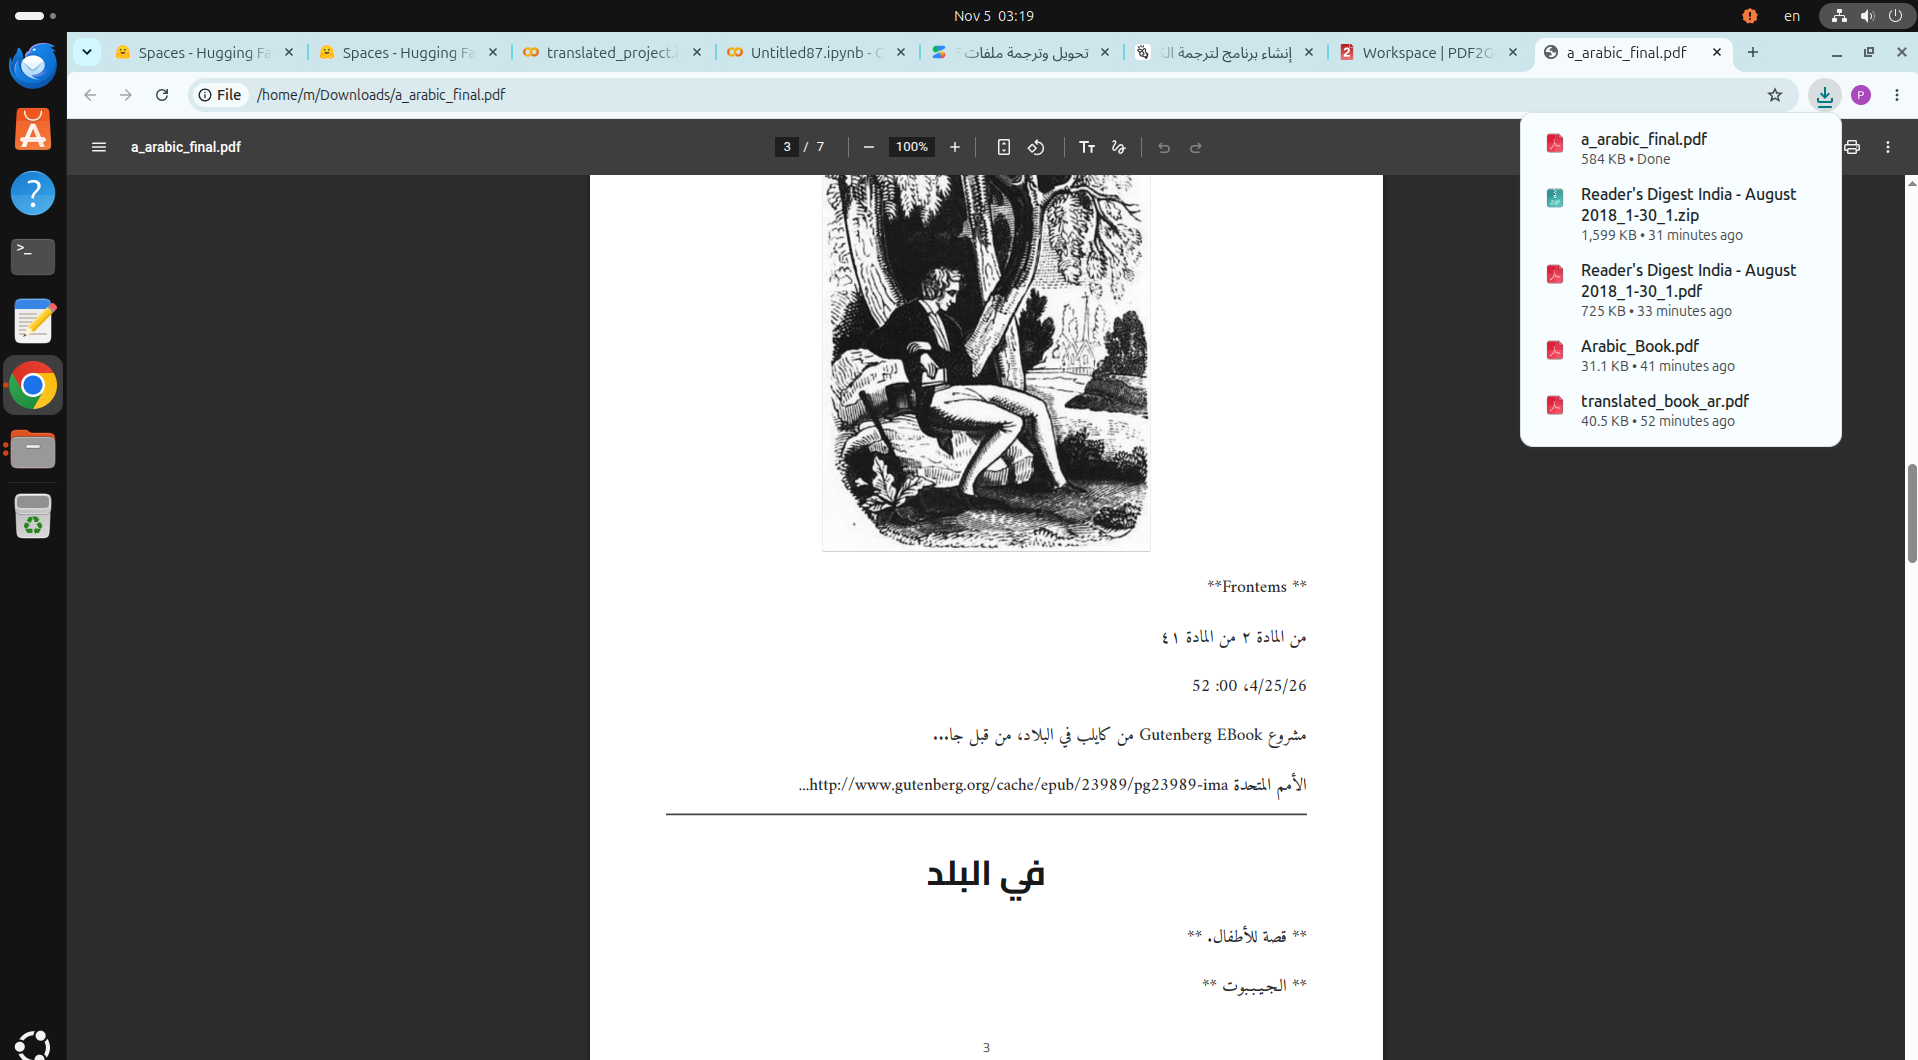

In [10]:
from IPython.display import Image, display

# تحديد مسار الصورة
image_path = '/content/Screenshot From 2026-11-05 03-19-26.png'

# عرض الصورة مع إمكانية التحكم في العرض (width)
display(Image(filename=image_path, width=600))

### الطريقة الثانية: استخدام مكتبة `PIL` ومكتبة `matplotlib`

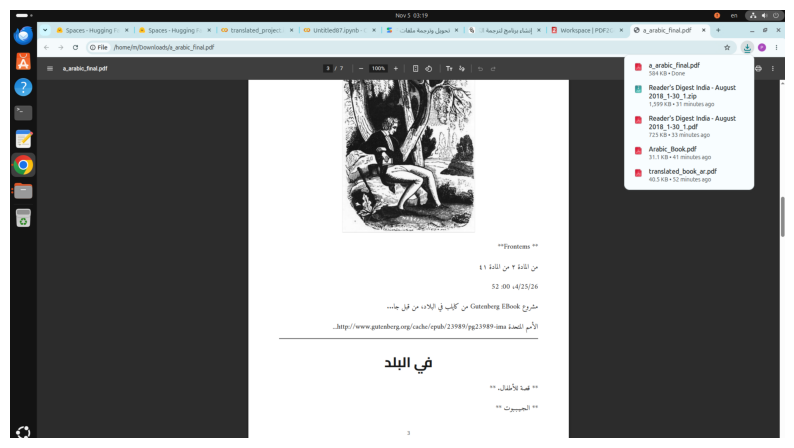

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

# فتح الصورة باستخدام PIL
img = Image.open('/content/Screenshot From 2026-11-05 03-19-26.png')

# عرض الصورة باستخدام matplotlib لتسهيل التحكم بالتحجيم والمحاور
plt.figure(figsize=(10, 6))
plt.imshow(img)
plt.axis('off') # لإخفاء أرقام المحاور الهندسية
plt.show()

In [11]:
import os
import re
import json
import torch
import gc
import markdown
import pymupdf4llm
from weasyprint import HTML
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# 1. إعداد النموذج
print("[*] جاري تحميل النموذج...")
model_name = "Helsinki-NLP/opus-mt-en-ar"
device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(device)

def step1_extract(pdf_path, output_dir):
    os.makedirs(output_dir, exist_ok=True)
    images_dir = os.path.abspath(os.path.join(output_dir, "images"))
    os.makedirs(images_dir, exist_ok=True)

    print(f"[*] 1. استخراج المحتوى من {pdf_path}...")
    md_text = pymupdf4llm.to_markdown(
        pdf_path,
        write_images=True,
        image_path=images_dir,
        image_format="png"
    )

    def fix_img_path(match):
        alt = match.group(1)
        src = match.group(2)
        filename = os.path.basename(src)
        abs_path = os.path.join(images_dir, filename)
        return f"![{alt}](file://{abs_path})"

    md_text = re.sub(r"!\[(.*?)\]\((.*?)\)", fix_img_path, md_text)
    return md_text

def translate_sentences_safe(sentences, batch_size=8):
    """ترجمة على دفعات صغيرة لتفادي CUDA Out of Memory"""
    translated_all = []
    for i in range(0, len(sentences), batch_size):
        batch = sentences[i:i + batch_size]
        try:
            inputs = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=512).to(device)
            with torch.no_grad():
                outputs = model.generate(**inputs)
            translated_all.extend(tokenizer.batch_decode(outputs, skip_special_tokens=True))
        except Exception:
            translated_all.extend(batch)
    return " ".join(translated_all)

def step2_translate_with_cache(md_text, cache_file):
    """ترجمة تدعم الاستئناف التلقائي وحفظ التقدم للكتب الكبيرة"""
    print("[*] 2. جاري تجهيز النص والترجمة (مع الحفظ التلقائي)...")

    # عزل الصور
    images_list = []
    def stash_image(match):
        idx = len(images_list)
        images_list.append(match.group(0))
        return f"\n\n__IMG_TOKEN_{idx}__\n\n"

    protected_text = re.sub(r"!\[.*?\]\(file://.*?\)", stash_image, md_text)
    paragraphs = [p.strip() for p in protected_text.split("\n\n") if p.strip()]

    # تحميل التقدم السابق إن وجد
    cache_data = {}
    if os.path.exists(cache_file):
        try:
            with open(cache_file, "r", encoding="utf-8") as f:
                cache_data = json.load(f)
            print(f"[i] تم العثور على تقدم محفوظ مسبقاً: تم إنجاز {len(cache_data)} فقرة.")
        except Exception:
            cache_data = {}

    total = len(paragraphs)
    translated_paras = []

    for idx, p in enumerate(paragraphs):
        str_idx = str(idx)

        # استرجاع الفقرة من الذاكرة إذا كانت مترجمة مسبقاً
        if str_idx in cache_data:
            translated_paras.append(cache_data[str_idx])
            continue

        if "__IMG_TOKEN_" in p:
            result = p
        else:
            raw_sents = [s.strip() for s in re.split(r'(?<=[.!?\n])\s+', p) if s.strip()]
            if raw_sents:
                result = translate_sentences_safe(raw_sents)
            else:
                result = p

        translated_paras.append(result)
        cache_data[str_idx] = result

        # حفظ التقدم كل 10 فقرات
        if (idx + 1) % 10 == 0 or (idx + 1) == total:
            with open(cache_file, "w", encoding="utf-8") as f:
                json.dump(cache_data, f, ensure_ascii=False)
            print(f"    - تم إنجاز {idx+1}/{total} فقرة (تم الحفظ التلقائي)")

            # تنظيف الذاكرة
            if device == "cuda":
                torch.cuda.empty_cache()
            gc.collect()

    # إعادة دمج الصور
    full_text = "\n\n".join(translated_paras)
    for i, img in enumerate(images_list):
        full_text = full_text.replace(f"__IMG_TOKEN_{i}__", img)

    return full_text

def step3_generate_pdf(translated_md, output_pdf):
    print("[*] 3. جاري توليد ملف الـ PDF النهائي...")
    html_body = markdown.markdown(translated_md, extensions=['tables', 'fenced_code'])

    html_template = f"""
    <!DOCTYPE html>
    <html dir="rtl" lang="ar">
    <head>
        <meta charset="utf-8">
        <style>
            @import url('https://fonts.googleapis.com/css2?family=Cairo:wght@400;700&family=Amiri:wght@400;700&display=swap');
            @page {{
                size: A4;
                margin: 20mm;
                @bottom-center {{
                    content: counter(page);
                    font-family: 'Cairo', sans-serif;
                    font-size: 10pt;
                }}
            }}
            body {{
                font-family: 'Amiri', 'Traditional Arabic', serif;
                direction: rtl;
                text-align: right;
                font-size: 12.5pt;
                line-height: 1.8;
            }}
            h1, h2, h3 {{ font-family: 'Cairo', sans-serif; text-align: center; }}
            p {{ text-align: justify; margin-bottom: 10px; }}
            img {{
                max-width: 80%;
                max-height: 450px;
                display: block;
                margin: 20px auto;
            }}
        </style>
    </head>
    <body>
        {html_body}
    </body>
    </html>
    """
    HTML(string=html_template).write_pdf(output_pdf)
    print(f"\n[+] اكتمل إنتاج الكتاب بنجاح: {output_pdf}")

# ==================== التشغيل ====================
SOURCE_PDF = "a.pdf"
WORKSPACE_DIR = "/content/translated_project"
CACHE_FILE = os.path.join(WORKSPACE_DIR, "translation_checkpoint.json")
FINAL_RESULT_PDF = os.path.join(WORKSPACE_DIR, "Book_Arabic_Final.pdf")

md_content = step1_extract(SOURCE_PDF, WORKSPACE_DIR)
ar_md = step2_translate_with_cache(md_content, CACHE_FILE)
step3_generate_pdf(ar_md, FINAL_RESULT_PDF)

[*] جاري تحميل النموذج...


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

[*] 1. استخراج المحتوى من a.pdf...

=== Document parser messages ===
Using RapidOCR & Tesseract for OCR processing.
OCR on page.number=0/1.
[*] 2. جاري تجهيز النص والترجمة (مع الحفظ التلقائي)...
    - تم إنجاز 10/11 فقرة (تم الحفظ التلقائي)
    - تم إنجاز 11/11 فقرة (تم الحفظ التلقائي)
[*] 3. جاري توليد ملف الـ PDF النهائي...



[+] اكتمل إنتاج الكتاب بنجاح: /content/translated_project/Book_Arabic_Final.pdf


In [14]:
import os
import re
import json
import torch
import gc
import markdown
import pymupdf4llm
from weasyprint import HTML
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# 1. إعداد النموذج
print("[*] جاري تحميل النموذج...")
model_name = "Helsinki-NLP/opus-mt-en-ar"
device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(device)

def step1_extract(pdf_path, output_dir):
    os.makedirs(output_dir, exist_ok=True)
    images_dir = os.path.abspath(os.path.join(output_dir, "images"))
    os.makedirs(images_dir, exist_ok=True)

    print(f"[*] 1. استخراج المحتوى من {pdf_path}...")
    md_text = pymupdf4llm.to_markdown(
        pdf_path,
        write_images=True,
        image_path=images_dir,
        image_format="png"
    )

    def fix_img_path(match):
        alt = match.group(1)
        src = match.group(2)
        filename = os.path.basename(src)
        abs_path = os.path.join(images_dir, filename)
        return f"![{alt}](file://{abs_path})"

    md_text = re.sub(r"!\[(.*?)\]\((.*?)\)", fix_img_path, md_text)
    return md_text

def translate_sentences_safe(sentences, batch_size=8):
    """ترجمة على دفعات صغيرة لتفادي CUDA Out of Memory"""
    translated_all = []
    for i in range(0, len(sentences), batch_size):
        batch = sentences[i:i + batch_size]
        try:
            inputs = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=512).to(device)
            with torch.no_grad():
                outputs = model.generate(**inputs)
            translated_all.extend(tokenizer.batch_decode(outputs, skip_special_tokens=True))
        except Exception:
            translated_all.extend(batch)
    return " ".join(translated_all)

def step2_translate_with_cache(md_text, cache_file):
    """ترجمة تدعم الاستئناف التلقائي وحفظ التقدم للكتب الكبيرة"""
    print("[*] 2. جاري تجهيز النص والترجمة (مع الحفظ التلقائي)...")

    # عزل الصور
    images_list = []
    def stash_image(match):
        idx = len(images_list)
        images_list.append(match.group(0))
        return f"\n\n__IMG_TOKEN_{idx}__\n\n"

    protected_text = re.sub(r"!\[.*?\]\(file://.*?\)", stash_image, md_text)
    paragraphs = [p.strip() for p in protected_text.split("\n\n") if p.strip()]

    # تحميل التقدم السابق إن وجد
    cache_data = {}
    if os.path.exists(cache_file):
        try:
            with open(cache_file, "r", encoding="utf-8") as f:
                cache_data = json.load(f)
            print(f"[i] تم العثور على تقدم محفوظ مسبقاً: تم إنجاز {len(cache_data)} فقرة.")
        except Exception:
            cache_data = {}

    total = len(paragraphs)
    translated_paras = []

    for idx, p in enumerate(paragraphs):
        str_idx = str(idx)

        # استرجاع الفقرة من الذاكرة إذا كانت مترجمة مسبقاً
        if str_idx in cache_data:
            translated_paras.append(cache_data[str_idx])
            continue

        if "__IMG_TOKEN_" in p:
            result = p
        else:
            raw_sents = [s.strip() for s in re.split(r'(?<=[.!?\n])\s+', p) if s.strip()]
            if raw_sents:
                result = translate_sentences_safe(raw_sents)
            else:
                result = p

        translated_paras.append(result)
        cache_data[str_idx] = result

        # حفظ التقدم كل 10 فقرات
        if (idx + 1) % 10 == 0 or (idx + 1) == total:
            with open(cache_file, "w", encoding="utf-8") as f:
                json.dump(cache_data, f, ensure_ascii=False)
            print(f"    - تم إنجاز {idx+1}/{total} فقرة (تم الحفظ التلقائي)")

            # تنظيف الذاكرة
            if device == "cuda":
                torch.cuda.empty_cache()
            gc.collect()

    # إعادة دمج الصور
    full_text = "\n\n".join(translated_paras)
    for i, img in enumerate(images_list):
        full_text = full_text.replace(f"__IMG_TOKEN_{i}__", img)

    return full_text

def step3_generate_pdf(translated_md, output_pdf):
    print("[*] 3. جاري توليد ملف الـ PDF النهائي...")
    html_body = markdown.markdown(translated_md, extensions=['tables', 'fenced_code'])

    html_template = f"""
    <!DOCTYPE html>
    <html dir="rtl" lang="ar">
    <head>
        <meta charset="utf-8">
        <style>
            @import url('https://fonts.googleapis.com/css2?family=Cairo:wght@400;700&family=Amiri:wght@400;700&display=swap');
            @page {{
                size: A4;
                margin: 20mm;
                @bottom-center {{
                    content: counter(page);
                    font-family: 'Cairo', sans-serif;
                    font-size: 10pt;
                }}
            }}
            body {{
                font-family: 'Amiri', 'Traditional Arabic', serif;
                direction: rtl;
                text-align: right;
                font-size: 12.5pt;
                line-height: 1.8;
            }}
            h1, h2, h3 {{ font-family: 'Cairo', sans-serif; text-align: center; }}
            p {{ text-align: justify; margin-bottom: 10px; }}
            img {{
                max-width: 80%;
                max-height: 450px;
                display: block;
                margin: 20px auto;
            }}
        </style>
    </head>
    <body>
        {html_body}
    </body>
    </html>
    """
    HTML(string=html_template).write_pdf(output_pdf)
    print(f"\n[+] اكتمل إنتاج الكتاب بنجاح: {output_pdf}")

# ==================== التشغيل ====================
SOURCE_PDF = "a.pdf"
WORKSPACE_DIR = "/content/translated_project"
CACHE_FILE = os.path.join(WORKSPACE_DIR, "translation_checkpoint.json")
FINAL_RESULT_PDF = os.path.join(WORKSPACE_DIR, "Book_Arabic_Final.pdf")

md_content = step1_extract(SOURCE_PDF, WORKSPACE_DIR)
ar_md = step2_translate_with_cache(md_content, CACHE_FILE)
step3_generate_pdf(ar_md, FINAL_RESULT_PDF)

[*] جاري تحميل النموذج...


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

[*] 1. استخراج المحتوى من a.pdf...


TypeError: '<' not supported between instances of 'str' and 'list'

In [15]:
!rm -rf /content/translated_project

### شغال كتاب كبير

In [16]:
import os
import re
import json
import gc
import torch
import markdown
import fitz  # PyMuPDF
import pymupdf4llm
from weasyprint import HTML
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# ==========================================
# 0. إعداد وتجهيز نموذج الذكاء الاصطناعي (مجاني ومحلي)
# ==========================================
print("[*] جاري تحميل نموذج الترجمة ومجزئ النصوص (Helsinki-NLP/opus-mt-en-ar)...")
MODEL_NAME = "Helsinki-NLP/opus-mt-en-ar"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(DEVICE)
print(f"[+] تم تحميل النموذج بنجاح (المعالج النشط: {DEVICE.upper()})")


# ==========================================
# 1. استخراج النص والصور بنظام الحماية ضد أخطاء OCR
# ==========================================
def step1_extract(pdf_path, output_dir):
    """
    استخراج Markdown والصور وحفظها بمسارات مطلقة،
    مع وجود نظام بديل (Fallback) في حال فشل الـ Layout Parser.
    """
    os.makedirs(output_dir, exist_ok=True)
    images_dir = os.path.abspath(os.path.join(output_dir, "images"))
    os.makedirs(images_dir, exist_ok=True)

    print(f"\n[*] 1. استخراج المحتوى والصور من: {pdf_path}...")

    md_text = ""
    # المحاولة الأولى: عبر pymupdf4llm بدون OCR لتجنب مشاكل RapidOCR
    try:
        md_text = pymupdf4llm.to_markdown(
            pdf_path,
            write_images=True,
            image_path=images_dir,
            image_format="png",
            use_ocr=False
        )
    except Exception as e:
        print(f"[!] تنبيه: تعذر الاستخراج عبر الموزع المتقدم ({e})، جاري التبديل للمستخرج المباشر Failsafe...")

        # المحاولة البديلة: استخراج مباشر عبر fitz (مستقر 100% ولا يتعطل أبداً)
        doc = fitz.open(pdf_path)
        chunks = []
        img_idx = 0

        for pno in range(len(doc)):
            page = doc[pno]

            # استخراج صور الصفحة
            for img_info in page.get_images(full=True):
                xref = img_info[0]
                base_img = doc.extract_image(xref)
                img_bytes = base_img["image"]
                img_ext = base_img["ext"]
                img_name = f"page_{pno+1}_img_{img_idx}.{img_ext}"
                img_path = os.path.join(images_dir, img_name)

                with open(img_path, "wb") as f_img:
                    f_img.write(img_bytes)

                chunks.append(f"![image](file://{img_path})")
                img_idx += 1

            # استخراج النص
            page_text = page.get_text("text").strip()
            if page_text:
                chunks.append(page_text)

        md_text = "\n\n".join(chunks)

    # توحيد مسارات الصور إلى صيغة مسار مطلق file://
    def fix_img_path(match):
        alt = match.group(1)
        src = match.group(2)
        if src.startswith("file://"):
            return match.group(0)
        filename = os.path.basename(src)
        abs_path = os.path.join(images_dir, filename)
        return f"![{alt}](file://{abs_path})"

    md_text = re.sub(r"!\[(.*?)\]\((.*?)\)", fix_img_path, md_text)

    extracted_imgs = os.listdir(images_dir)
    print(f"[+] تم استخراج النص وحفظ {len(extracted_imgs)} صورة في مجلد: {images_dir}")
    return md_text


# ==========================================
# 2. الترجمة الآمنة على دفعات صغيرة لتفادي انهيار الذاكرة
# ==========================================
def translate_sentences_batch(sentences, batch_size=8):
    """ترجمة مجموعة جمل كدفعة واحدة (Batch) لحماية كارت الشاشة وتسريع الأداء"""
    translated_all = []
    for i in range(0, len(sentences), batch_size):
        batch = sentences[i:i + batch_size]
        try:
            inputs = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=512).to(DEVICE)
            with torch.no_grad():
                outputs = model.generate(**inputs)
            decoded = tokenizer.batch_decode(outputs, skip_special_tokens=True)
            translated_all.extend(decoded)
        except Exception as e:
            # في حال حدوث أي خطأ في جملة ما، نحتفظ بالنص بدلاً من توقف البرنامج
            translated_all.extend(batch)
    return " ".join(translated_all)


# ==========================================
# 3. محرك الترجمة للكتب الكبيرة مع ميزة الحفظ التلقائي (Checkpoint)
# ==========================================
def step2_translate_large_book(md_text, cache_file):
    """
    يترجم الكتاب فقرة بفقرة، مع حفظ دوري يمنع ضياع التقدم
    لو انقطع الاتصال أو أغلقت الجلسة.
    """
    print("\n[*] 2. جاري تجهيز النص والترجمة بنظام الحفظ التلقائي للكتب الكبيرة...")

    # عزل علامات الصور
    images_list = []
    def stash_image(match):
        idx = len(images_list)
        images_list.append(match.group(0))
        return f"\n\n__IMG_TOKEN_{idx}__\n\n"

    protected_text = re.sub(r"!\[.*?\]\(file://.*?\)", stash_image, md_text)
    paragraphs = [p.strip() for p in protected_text.split("\n\n") if p.strip()]

    # استعادة التقدم المحفوظ من قبل
    cache_data = {}
    if os.path.exists(cache_file):
        try:
            with open(cache_file, "r", encoding="utf-8") as f:
                cache_data = json.load(f)
            print(f"[i] تم العثور على تقدم محفوظ مسبقاً: سيتم استكمال العمل من الفقرة ({len(cache_data)}).")
        except Exception:
            cache_data = {}

    total = len(paragraphs)
    translated_paras = []

    for idx, p in enumerate(paragraphs):
        str_idx = str(idx)

        # إذا كانت الفقرة مترجمة مسبقاً في ملف الـ Checkpoint نتجاوزها فوراً
        if str_idx in cache_data:
            translated_paras.append(cache_data[str_idx])
            continue

        if "__IMG_TOKEN_" in p:
            result = p
        else:
            # تقسيم الفقرة إلى جمل بناءً على علامات الترقيم
            raw_sents = [s.strip() for s in re.split(r'(?<=[.!?\n])\s+', p) if s.strip()]
            if raw_sents:
                result = translate_sentences_batch(raw_sents, batch_size=8)
            else:
                result = p

        translated_paras.append(result)
        cache_data[str_idx] = result

        # حفظ التقدم كل 10 فقرات وتنظيف الذاكرة
        if (idx + 1) % 10 == 0 or (idx + 1) == total:
            with open(cache_file, "w", encoding="utf-8") as f:
                json.dump(cache_data, f, ensure_ascii=False)

            progress_pct = ((idx + 1) / total) * 100
            print(f"    - تقدم الترجمة: {idx+1}/{total} فقرة ({progress_pct:.1f}%) [محفوظ تلقائياً]")

            # تفريغ ذاكرة الرام وكارت الشاشة لمنع انهيار الجلسة
            if DEVICE == "cuda":
                torch.cuda.empty_cache()
            gc.collect()

    # إعادة دمج وسوم الصور في أماكنها الصحيحة
    full_text = "\n\n".join(translated_paras)
    for i, img in enumerate(images_list):
        full_text = full_text.replace(f"__IMG_TOKEN_{i}__", img)

    return full_text


# ==========================================
# 4. توليد الـ PDF بتنسيق عربي فاخر وضبط الصور
# ==========================================
def step3_generate_pdf(translated_md, output_pdf):
    print("\n[*] 3. جاري تحويل الـ Markdown إلى ملف PDF نهائي...")

    # تحويل Markdown إلى HTML
    html_body = markdown.markdown(translated_md, extensions=['tables', 'fenced_code'])

    # قالب HTML مهيأ للكتاب العربي
    html_template = f"""
    <!DOCTYPE html>
    <html dir="rtl" lang="ar">
    <head>
        <meta charset="utf-8">
        <style>
            @import url('https://fonts.googleapis.com/css2?family=Cairo:wght@400;600;700&family=Amiri:wght@400;700&display=swap');

            @page {{
                size: A4;
                margin: 22mm 18mm;
                @bottom-center {{
                    content: counter(page);
                    font-family: 'Cairo', sans-serif;
                    font-size: 10pt;
                    color: #555;
                }}
            }}
            body {{
                font-family: 'Amiri', 'Traditional Arabic', serif;
                direction: rtl;
                text-align: right;
                font-size: 13pt;
                line-height: 1.85;
                color: #222;
            }}
            h1, h2, h3 {{
                font-family: 'Cairo', sans-serif;
                text-align: center;
                color: #111;
                margin-top: 30px;
                margin-bottom: 15px;
            }}
            p {{
                text-align: justify;
                margin-bottom: 12px;
            }}
            /* تنسيق عرض الصور لمنع انكسار الصفحات */
            img {{
                max-width: 85%;
                max-height: 480px;
                display: block;
                margin: 25px auto;
                border: 1px solid #ddd;
                page-break-inside: avoid;
            }}
            pre, code {{
                direction: ltr;
                text-align: left;
            }}
        </style>
    </head>
    <body>
        {html_body}
    </body>
    </html>
    """

    HTML(string=html_template).write_pdf(output_pdf)
    print(f"\n[+] اكتمل إنشاء الكتاب بنجاح تام! المسار:\n{output_pdf}")


# ==========================================
# تشغيل البرنامج
# ==========================================
if __name__ == "__main__":
    # حدد اسم ملف الـ PDF الخاص بك هنا
    SOURCE_PDF = "a.pdf"

    # مجلد العمل ومكان حفظ الملفات الناتجة
    WORKSPACE_DIR = "/content/translated_project"

    # ملف الحفظ التلقائي (Checkpoint)
    CHECKPOINT_FILE = os.path.join(WORKSPACE_DIR, "translation_checkpoint.json")

    # اسم ملف الـ PDF النهائي المترجم
    FINAL_RESULT_PDF = os.path.join(WORKSPACE_DIR, "Book_Arabic_Final.pdf")

    # 1. الاستخراج
    md_content = step1_extract(SOURCE_PDF, WORKSPACE_DIR)

    # 2. الترجمة الآمنة مع الحفظ التلقائي
    ar_md = step2_translate_large_book(md_content, CHECKPOINT_FILE)

    # حفظ نسخة من ملف الـ Markdown المترجم للمعاينة
    translated_md_path = os.path.join(WORKSPACE_DIR, "translated_book.md")
    with open(translated_md_path, "w", encoding="utf-8") as f:
        f.write(ar_md)
    print(f"[+] تم حفظ نسخة Markdown مترجمة في: {translated_md_path}")

    # 3. بناء الـ PDF العربي النهائي
    step3_generate_pdf(ar_md, FINAL_RESULT_PDF)

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


[*] جاري تحميل نموذج الترجمة ومجزئ النصوص (Helsinki-NLP/opus-mt-en-ar)...


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

[+] تم تحميل النموذج بنجاح (المعالج النشط: CPU)

[*] 1. استخراج المحتوى والصور من: a.pdf...

=== Document parser messages ===
Using RapidOCR & Tesseract for OCR processing.
Using RapidOCR & Tesseract for OCR processing.
[+] تم استخراج النص وحفظ 3 صورة في مجلد: /content/translated_project/images

[*] 2. جاري تجهيز النص والترجمة بنظام الحفظ التلقائي للكتب الكبيرة...
    - تقدم الترجمة: 10/52 فقرة (19.2%) [محفوظ تلقائياً]
    - تقدم الترجمة: 20/52 فقرة (38.5%) [محفوظ تلقائياً]
    - تقدم الترجمة: 30/52 فقرة (57.7%) [محفوظ تلقائياً]
    - تقدم الترجمة: 40/52 فقرة (76.9%) [محفوظ تلقائياً]
    - تقدم الترجمة: 50/52 فقرة (96.2%) [محفوظ تلقائياً]
    - تقدم الترجمة: 52/52 فقرة (100.0%) [محفوظ تلقائياً]
[+] تم حفظ نسخة Markdown مترجمة في: /content/translated_project/translated_book.md

[*] 3. جاري تحويل الـ Markdown إلى ملف PDF نهائي...



[+] اكتمل إنشاء الكتاب بنجاح تام! المسار:
/content/translated_project/Book_Arabic_Final.pdf


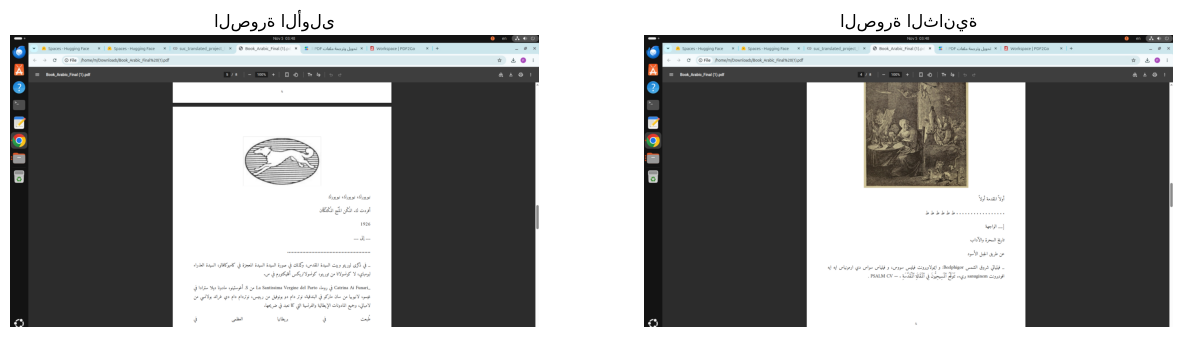

In [19]:
import matplotlib.pyplot as plt
from PIL import Image

# فتح الصورتين بشكل منفصل لتجنب خطأ bad mode
img1 = Image.open('/content/zz111.png')
img2 = Image.open('/content/zzz3.png')

# إنشاء إطار لعرض الصورتين جنباً إلى جنب
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# عرض الصورة الأولى
axes[0].imshow(img1)
axes[0].axis('off')
axes[0].set_title('الصورة الأولى')

# عرض الصورة الثانية
axes[1].imshow(img2)
axes[1].axis('off')
axes[1].set_title('الصورة الثانية')

plt.show()

In [ ]:
الخيار 2: نموذج محلي قوي بدون إنترنت (Meta NLLB-200)
إذا كنت ترفض تماماً استخدام أي مفاتيح API وتريد نموذجاً يعمل محلياً على كارت الشاشة (GPU)، يمكنك استخدام نموذج شركة ميتا الشهير:
facebook/nllb-200-distilled-600M أو facebook/nllb-200-1.3B.
هو أفضل بكثير من Helsinki، لكنه يظل أقل بلاغة من نماذج المحادثة الذكية مثل Gemini.

In [ ]:
!apt-get install -y pango1.0-tools
!pip install -q -U transformers accelerate sentencepiece pymupdf pymupdf4llm markdown weasyprint

In [ ]:
import os
import re
import json
import gc
import torch
import markdown
import fitz  # PyMuPDF
import pymupdf4llm
from weasyprint import HTML
from transformers import pipeline

# ==========================================================
# 0. الإعدادات ومفتاح Hugging Face
# ==========================================================
# ضع رمز الوصول الخاص بك من Hugging Face هنا
HF_TOKEN = "hf_xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx"

# إعداد مسارات الملفات
SOURCE_PDF = "1_01.pdf"  # اسم كتابك الأصلي
WORKSPACE_DIR = "/content/translated_project"
CHECKPOINT_FILE = os.path.join(WORKSPACE_DIR, "translategemma_checkpoint.json")
FINAL_RESULT_PDF = os.path.join(WORKSPACE_DIR, "Book_Arabic_TranslateGemma.pdf")


# ==========================================================
# 1. تحميل نموذج TranslateGemma 4B على الـ GPU
# ==========================================================
def load_translategemma(token):
    print("\n[*] جاري تحميل نموذج google/translategemma-4b-it على كارت الشاشة...")
    device = "cuda" if torch.cuda.is_available() else "cpu"

    if device != "cuda":
        print("[!] تحذير: أنت تعمل على المعالج CPU، يرجى تفعيل T4 GPU لتجنب البطء الشديد.")

    pipe = pipeline(
        "image-text-to-text",
        model="google/translategemma-4b-it",
        device=device,
        torch_dtype=torch.bfloat16 if torch.cuda.is_available() else torch.float32,
        token=token
    )
    print(f"[+] تم تحميل النموذج بنجاح وهو جاهز للعمل على: {device.upper()}")
    return pipe


# ==========================================================
# 2. استخراج النص والصور بنظام حماية ضد أخطاء OCR
# ==========================================================
def step1_extract(pdf_path, output_dir):
    os.makedirs(output_dir, exist_ok=True)
    images_dir = os.path.abspath(os.path.join(output_dir, "images"))
    os.makedirs(images_dir, exist_ok=True)

    print(f"\n[*] 1. جاري استخراج النص والصور من {pdf_path}...")

    md_text = ""
    # المحاولة الأولى: عبر pymupdf4llm مع إيقاف use_ocr لتفادي انهيار RapidOCR
    try:
        md_text = pymupdf4llm.to_markdown(
            pdf_path,
            write_images=True,
            image_path=images_dir,
            image_format="png",
            use_ocr=False
        )
    except Exception as e:
        print(f"[!] تنبيه: جاري التحويل للمستخرج المباشر Failsafe بسبب: {e}")
        doc = fitz.open(pdf_path)
        chunks = []
        img_idx = 0
        for pno in range(len(doc)):
            page = doc[pno]
            # استخراج الصور
            for img_info in page.get_images(full=True):
                xref = img_info[0]
                base_img = doc.extract_image(xref)
                img_name = f"page_{pno+1}_img_{img_idx}.{base_img['ext']}"
                img_path = os.path.join(images_dir, img_name)
                with open(img_path, "wb") as f_img:
                    f_img.write(base_img["image"])
                chunks.append(f"![image](file://{img_path})")
                img_idx += 1
            # استخراج النص
            text = page.get_text("text").strip()
            if text:
                chunks.append(text)
        md_text = "\n\n".join(chunks)

    # ضبط جميع مسارات الصور كمسارات مطلقة بصيغة file:// لضمان ظهورها في الـ PDF
    def fix_img_path(match):
        alt = match.group(1)
        src = match.group(2)
        if src.startswith("file://"):
            return match.group(0)
        filename = os.path.basename(src)
        abs_path = os.path.join(images_dir, filename)
        return f"![{alt}](file://{abs_path})"

    md_text = re.sub(r"!\[(.*?)\]\((.*?)\)", fix_img_path, md_text)
    extracted_imgs = os.listdir(images_dir)
    print(f"[+] تم استخراج النص وحفظ {len(extracted_imgs)} صورة داخل: {images_dir}")
    return md_text


# ==========================================================
# 3. محرك الترجمة للكتب الكبيرة مع الحفظ التلقائي (Checkpoint)
# ==========================================================
def step2_translate_large_book(pipe, md_text, cache_file):
    print("\n[*] 2. جاري تجهيز النص والترجمة بنظام الحفظ التلقائي...")

    # عزل الصور وحمايتها برموز مؤقتة حتى لا تُشوه بالترجمة
    images_list = []
    def stash_image(match):
        idx = len(images_list)
        images_list.append(match.group(0))
        return f"\n\n__IMG_TOKEN_{idx}__\n\n"

    protected_text = re.sub(r"!\[.*?\]\(file://.*?\)", stash_image, md_text)
    paragraphs = [p.strip() for p in protected_text.split("\n\n") if p.strip()]

    # استرجاع التقدم المحفوظ مسبقاً (Checkpoint)
    cache_data = {}
    if os.path.exists(cache_file):
        try:
            with open(cache_file, "r", encoding="utf-8") as f:
                cache_data = json.load(f)
            print(f"[i] تم العثور على تقدم سابق: سيتم الاستئناف من الفقرة رقم ({len(cache_data)}).")
        except Exception:
            cache_data = {}

    total = len(paragraphs)
    translated_paras = []

    for idx, p in enumerate(paragraphs):
        str_idx = str(idx)

        # تجاوز الفقرات المترجمة مسبقاً
        if str_idx in cache_data:
            translated_paras.append(cache_data[str_idx])
            continue

        if "__IMG_TOKEN_" in p:
            result = p
        else:
            try:
                # التنسيق القياسي الخاص بنموذج TranslateGemma
                messages = [
                    {
                        "role": "user",
                        "content": [
                            {
                                "type": "text",
                                "source_lang_code": "en",
                                "target_lang_code": "ar",
                                "text": p
                            }
                        ]
                    }
                ]
                # توليد الترجمة
                out = pipe(text=messages, max_new_tokens=1024)
                result = out[0]["generated_text"][-1]["content"].strip()
            except Exception as e:
                print(f"[!] خطأ عابر في الفقرة {idx+1}: {e}")
                result = p

        translated_paras.append(result)
        cache_data[str_idx] = result

        # حفظ التقدم كل 5 فقرات وتنظيف الذاكرة
        if (idx + 1) % 5 == 0 or (idx + 1) == total:
            with open(cache_file, "w", encoding="utf-8") as f:
                json.dump(cache_data, f, ensure_ascii=False)

            pct = ((idx + 1) / total) * 100
            print(f"    - تقدم الترجمة: {idx+1}/{total} فقرة ({pct:.1f}%) [محفوظ تلقائياً]")

            # تفريغ ذاكرة الكارت والـ RAM دورياً لمنع الانهيار
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            gc.collect()

    # إعادة دمج الصور في أماكنها الأصلية
    full_text = "\n\n".join(translated_paras)
    for i, img in enumerate(images_list):
        full_text = full_text.replace(f"__IMG_TOKEN_{i}__", img)

    return full_text


# ==========================================================
# 4. بناء الـ PDF النهائي بتنسيق عربي فاخر
# ==========================================================
def step3_generate_pdf(translated_md, output_pdf):
    print("\n[*] 3. جاري توليد ملف الـ PDF العربي النهائي...")

    html_body = markdown.markdown(translated_md, extensions=['tables', 'fenced_code'])

    html_template = f"""
    <!DOCTYPE html>
    <html dir="rtl" lang="ar">
    <head>
        <meta charset="utf-8">
        <style>
            @import url('https://fonts.googleapis.com/css2?family=Cairo:wght@400;600;700&family=Amiri:wght@400;700&display=swap');
            @page {{
                size: A4;
                margin: 22mm 18mm;
                @bottom-center {{
                    content: counter(page);
                    font-family: 'Cairo', sans-serif;
                    font-size: 10pt;
                    color: #555;
                }}
            }}
            body {{
                font-family: 'Amiri', 'Traditional Arabic', serif;
                direction: rtl;
                text-align: right;
                font-size: 13pt;
                line-height: 1.85;
                color: #222;
            }}
            h1, h2, h3 {{
                font-family: 'Cairo', sans-serif;
                text-align: center;
                color: #111;
                margin-top: 30px;
                margin-bottom: 15px;
            }}
            p {{
                text-align: justify;
                margin-bottom: 12px;
            }}
            img {{
                max-width: 85%;
                max-height: 480px;
                display: block;
                margin: 25px auto;
                border: 1px solid #ddd;
                page-break-inside: avoid;
            }}
            pre, code {{
                direction: ltr;
                text-align: left;
            }}
        </style>
    </head>
    <body>
        {html_body}
    </body>
    </html>
    """

    HTML(string=html_template).write_pdf(output_pdf)
    print(f"\n[+] اكتمل إنشاء الكتاب بنجاح تام! المسار:\n{output_pdf}")


# ==========================================================
# نقطة الدخول والتشغيل
# ==========================================================
if __name__ == "__main__":
    # 1. تحميل النموذج
    translator_pipe = load_translategemma(HF_TOKEN)

    # 2. استخراج النص والصور
    md_content = step1_extract(SOURCE_PDF, WORKSPACE_DIR)

    # 3. الترجمة بنظام الحفظ التلقائي
    ar_md = step2_translate_large_book(translator_pipe, md_content, CHECKPOINT_FILE)

    # حفظ نسخة الـ Markdown المترجمة للمعاينة
    translated_md_path = os.path.join(WORKSPACE_DIR, "translated_book.md")
    with open(translated_md_path, "w", encoding="utf-8") as f:
        f.write(ar_md)
    print(f"[+] تم حفظ نسخة Markdown مترجمة في: {translated_md_path}")

    # 4. بناء ملف الـ PDF النهائي
    step3_generate_pdf(ar_md, FINAL_RESULT_PDF)